# Assignment 3: N24News EDA

Preparation only; no model training/results. Run the download/preparation commands in `assignment3/README.md` first. Select the `.venv-a3` kernel (install ipykernel in that environment if needed).

In [1]:
from pathlib import Path
import json
from collections import Counter
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/assignment3.yaml').exists())
run = 'subset_500_seed44_original'
metadata = json.loads((root / 'data/assignment3/raw/nytimes_dataset.json').read_text(encoding='utf-8'))
summary = json.loads((root / 'outputs/assignment3' / run / 'eda_summary.json').read_text(encoding='utf-8'))
print('Metadata records:', len(metadata))
print('Prepared pairs:', summary['prepared_pairs'])
print('Splits:', summary['split_counts'])

Metadata records: 61218
Prepared pairs: 12000
Splits: {'train': 9600, 'validation': 1200, 'test': 1200}


## Class distribution

The selected subset has a per-class cap of 500. Its class prior differs from the full corpus, so benchmark results are not directly comparable to the paper.

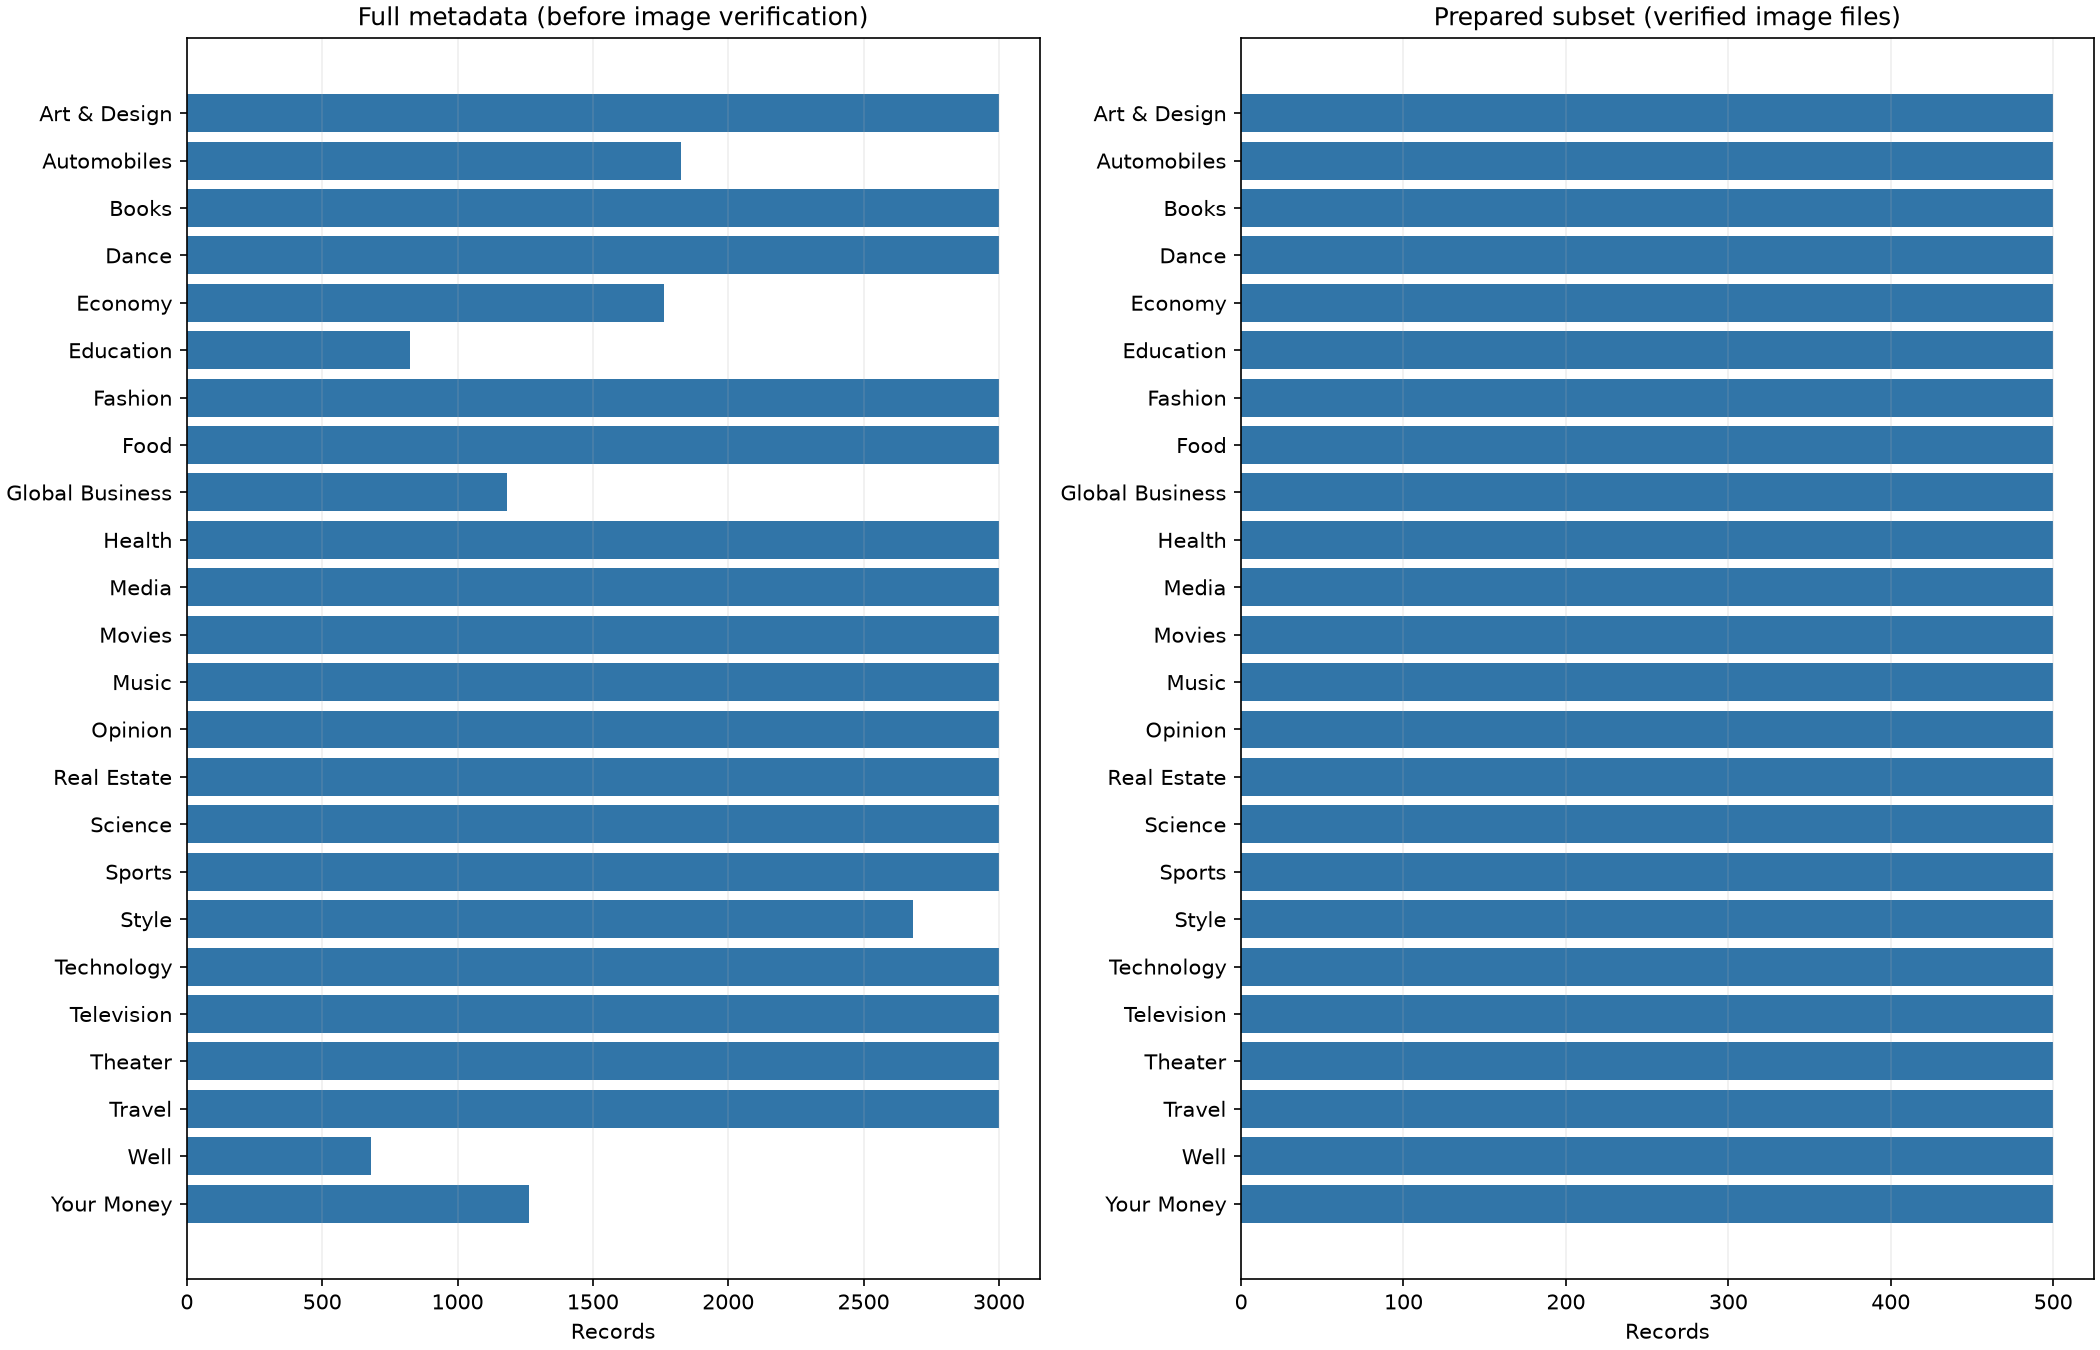

{'train': {'Art & Design': 400, 'Automobiles': 400, 'Books': 400, 'Dance': 400, 'Economy': 400, 'Education': 400, 'Fashion': 400, 'Food': 400, 'Global Business': 400, 'Health': 400, 'Media': 400, 'Movies': 400, 'Music': 400, 'Opinion': 400, 'Real Estate': 400, 'Science': 400, 'Sports': 400, 'Style': 400, 'Technology': 400, 'Television': 400, 'Theater': 400, 'Travel': 400, 'Well': 400, 'Your Money': 400}, 'validation': {'Art & Design': 50, 'Automobiles': 50, 'Books': 50, 'Dance': 50, 'Economy': 50, 'Education': 50, 'Fashion': 50, 'Food': 50, 'Global Business': 50, 'Health': 50, 'Media': 50, 'Movies': 50, 'Music': 50, 'Opinion': 50, 'Real Estate': 50, 'Science': 50, 'Sports': 50, 'Style': 50, 'Technology': 50, 'Television': 50, 'Theater': 50, 'Travel': 50, 'Well': 50, 'Your Money': 50}, 'test': {'Art & Design': 50, 'Automobiles': 50, 'Books': 50, 'Dance': 50, 'Economy': 50, 'Education': 50, 'Fashion': 50, 'Food': 50, 'Global Business': 50, 'Health': 50, 'Media': 50, 'Movies': 50, 'Music'

In [2]:
display(Image(filename=str(root / 'outputs/assignment3' / run / 'class_distribution.png')))
print(summary['split_class_counts'])

## Input length, dimensions and group-aware splits

Headline whitespace counts are not tokenizer counts. Broader event-level overlap is not completely identified by URL/image hashes.

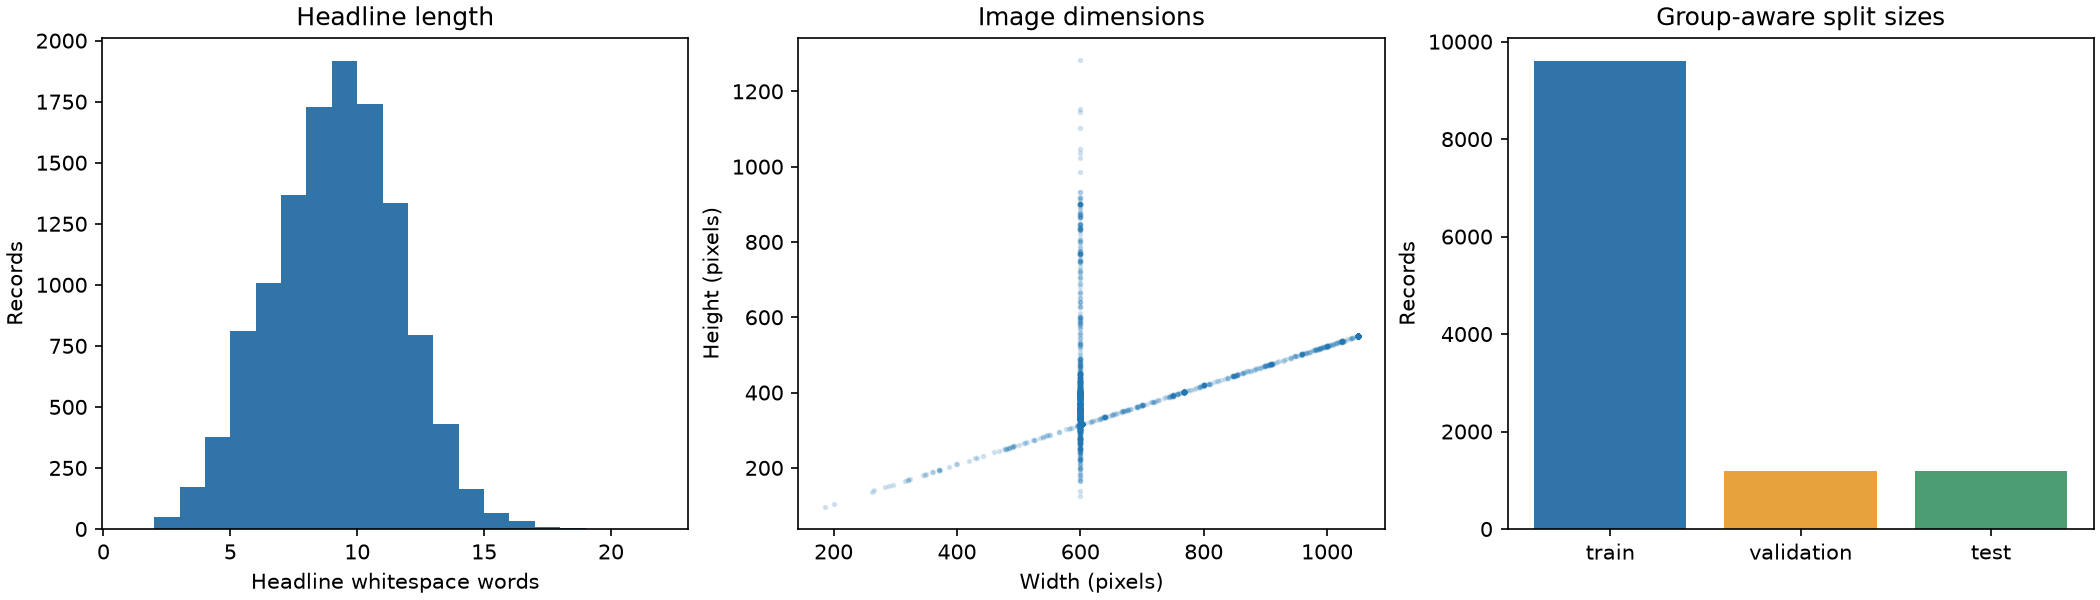

Passed: sample IDs, group IDs, pixel/file hashes, canonical image/article URLs and normalized exact headlines disjoint across splits
Full-metadata article/image canonical URL components; selected pixel/file hashes; normalized exact headlines grouped to prevent text memorization; strict perceptual similarity (dHash<=1, RGB thumbnail RMSE<=5, aspect delta<=0.05; flat images excluded)
No complete event-level IDs; broader semantic event overlap remains unverified. Identical headlines are grouped conservatively for text-overlap control, not claimed to be the same event.


In [3]:
display(Image(filename=str(root / 'outputs/assignment3' / run / 'input_and_split_stats.png')))
print(summary['leakage_checks'])
print(summary['group_rules'])
print(summary['limitation'])

## Pair quality review

Codex visually reviewed 120 pilot pairs (5 per class) using metadata URL rendering. The prepared subset uses original asset URLs. The review is AI-assisted and needs human verification; it is not a measured population noise rate.

In [ ]:
review = json.loads((root / 'outputs/assignment3/pilot_seed44/pair_review_summary.json').read_text(encoding='utf-8'))
print(review['ratings'])
print(review['observations'])
print('Human review form:', root / 'outputs/assignment3' / run / 'pair_review.csv')

{'clear_topic_support': 81, 'weak_contextual': 37, 'uncertain': 2}
['Many reviewed images contain an NYT Published-year rendering overlay. A same-asset URL without query parameters was checked visually and did not contain the overlay.', 'Generic portraits and editorial categories create weak image-only evidence.', 'Rows 66 and 68 visibly reuse the same medical transport scene.', 'No definite mismatch is claimed from image/headline inspection alone.']
Human review form: d:\261\DL\CO3133_Group05_Assignment\outputs\assignment3\subset_500_seed44_original\pair_review.csv


: 

## Next steps

Review the EDA and `assignment3/PROPOSAL.md`, verify usage conditions, and record instructor approval. Main training follows approval. This notebook is provided for reproducible inspection and has not been executed as a notebook; the underlying preparation script generates the verified reports and charts.